# 04. Slabs

- Teaches what a slab is and how to build one: the model of a surface that every adsorption and every reaction calculation of this course sits on
- Two tools build them here: `ase.build.fcc111` for the close-packed metal surfaces of this course, and pymatgen's `SlabGenerator` for everything else
- Before you start: modules 00 to 03 finished, the `mlip-mace` environment active, and Jupyter Lab running
    - The kernel shown at the top right of this notebook is "Python 3 (ipykernel)", the Python of that environment
- After this you can cut a slab out of a bulk crystal, count its layers, list its terminations, size it in plane, freeze its bottom and write it out for a calculation
- Nine canon items decide how a slab is built, and this module names every one of them
- Three of the nine are settled for the whole group, and every project follows them
    - `S6`: the shortest in-plane lattice vector of a surface or adsorption cell is about 7.5 Å; a vector below that is repeated until it clears the minimum
    - `S7`: slabs are cleaved from the bulk optimized at the project's own level of theory, never from idealized coordinates
    - `S9`: slab cells are never relaxed; the lateral cell parameters come from the optimized bulk
- Six of the nine are open, decided per project by your supervisor and written in the project's `CANON.md`
    - `S1`: the cleavage procedure, meaning the tool that cuts the slab and the settings it is given
    - `S2`: the slab thickness, and the precise definition of what counts as one layer
    - `S3`: whether the cut keeps the stoichiometry, and whether the top and the bottom of the slab are made the same
    - `S4`: which terminations to generate, for a material that has more than one
    - `S5`: the thickness of the vacuum region
    - `S8`: how many bottom layers are frozen, counted in the layer definition of `S2`
- The numbers used below are teaching values, chosen so that this notebook runs on a laptop in under a minute
    - They are not any project's answer to any of the nine items

## 0. The setup cell

- Run this cell first, every time you open the notebook
- This module uses the two structure packages of the course: ASE from module 02, and pymatgen from module 03
    - Each section below imports the part it needs, so you can see where every name comes from
    - The sections build on each other, so run them from top to bottom the first time
- `from pathlib import Path` takes the `Path` tool out of `pathlib`, which comes with Python
- `numpy` is imported here under the short name `np`, and `pandas` under `pd`, as in modules 01, 02 and 03
    - NumPy does the height arithmetic of this notebook, and pandas prints its tables
- `WORK` is the folder this notebook writes its own files into
    - `WORK.mkdir(exist_ok=True)` creates the folder, and does nothing if it is already there
    - The folder sits inside this module folder and is not saved to the repository
- `STRUCTURES` points at the shared structure files, two folder levels up
    - `STRUCTURES.exists()` answers `True` or `False`, and is worth asking before reading from it
    - A relative path such as `work` or `../../structures` is read from the folder this notebook file sits in, whatever folder Jupyter Lab was started from

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

WORK = Path("work")
WORK.mkdir(exist_ok=True)
STRUCTURES = Path("../../structures")

print("Folder this notebook writes into")
print(WORK)
print("Folder the starting structures come from")
print(STRUCTURES)
print("Does the structures folder exist")
print(STRUCTURES.exists())

Folder this notebook writes into
work
Folder the starting structures come from
../../structures
Does the structures folder exist
True


## 1. What a slab is

- A surface is where a material stops; catalysis happens there, so every calculation of this course needs a model of one
- A slab is that model: a piece of the bulk crystal, a few atomic planes thick, with empty space above it and below it
    - The cell still repeats in all three directions, as every cell in module 02 did
    - The empty space is what makes the repetition harmless in the third direction: the top of the slab is far enough from the bottom of its next copy that they do not feel each other
- The picture below is a finished slab of this course: platinum, the (1 1 1) surface, three atomic planes thick, 10 Å of empty space above and below
    - The section on the quick way explains the one line that built it
- In the figure:
    - Left, the side view: three rows of atoms with empty space over and under them, drawn inside the dotted cell
    - Right, the top view, looking down the z axis at the surface: all 27 atoms are drawn, the three layers offset from one another as a close-packed stacking is, with the top layer in front
    - The two panels are different views of the same 27 atoms, not two structures

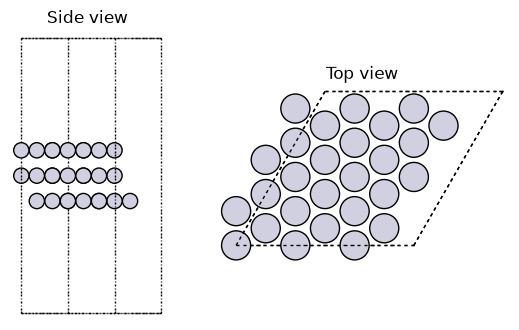

Atoms in the slab drawn above
27


In [2]:
import matplotlib.pyplot as plt
from ase.build import fcc111
from ase.visualize.plot import plot_atoms

demo_slab = fcc111("Pt", size=(3, 3, 3), a=3.92, vacuum=10.0)

fig, axes = plt.subplots(1, 2, figsize=(6, 3.4))

plot_atoms(demo_slab, axes[0], radii=0.5, rotation="-90x")
axes[0].set_title("Side view", fontsize=12)

plot_atoms(demo_slab, axes[1], radii=0.5)
axes[1].set_title("Top view", fontsize=12)

fig.tight_layout()
plt.show()

print("Atoms in the slab drawn above")
print(len(demo_slab))

### 1a. The words for the parts of a slab

- The nine words below are used by every later section, by the group's scripts, and by your supervisor
- Miller index: three whole numbers, written `(1 1 1)` or `(1 0 0)`, that name the plane the crystal is cut along
    - They are read against the axes of the conventional cell, the cell of module 03
    - A different Miller index is a different surface of the same material, with different atoms exposed and different chemistry
- Cleave: to cut the crystal along that plane; the two new faces it opens are the surfaces
- Surface normal: the direction perpendicular to the surface plane, the direction the surface looks along
    - In a well-behaved slab the surface normal is the z axis, and the section on the orthogonal cell shows what happens when it is not
- Layer: one atomic plane of the slab, parallel to the surface
    - The count is the slab thickness, and `S2` is the project decision that says both how many layers and what counts as one
- In-plane vector: one of the two cell vectors that lie in the surface plane
    - Their lengths set how far an adsorbate sits from its own periodic copy, which is what canon `S6` is about
- Vacuum: the empty space added above and below the slab, measured in Å
    - Too little and the slab reacts with its own copy; too much only wastes computer time
    - How much is canon `S5`, a project decision
- Termination: which atomic plane ends up on top after the cut
    - A metal with one atom per lattice point, as face-centred cubic platinum has, exposes the same plane wherever the cut falls, so it has one termination
    - An oxide has several, and they are different surfaces with different energies
    - Hexagonal close-packed cobalt already has two terminations on some of its faces, so the count is something to measure and never something to assume from the element
    - Which ones to compute is canon `S4`
- Frozen layer: a layer at the bottom of the slab whose atoms are not allowed to move during a relaxation
    - It holds the bulk geometry in place while the surface relaxes, which is what makes the slab a model of a surface and not of a thin film
    - How many layers are frozen is canon `S8`
- Adsorbate: an atom or molecule sitting on the surface; module 05 places them, and this module only builds the surface they sit on

## 2. The quick way: ase.build

- `ase.build` holds ready-made builders for the common surfaces, and they are the fastest way to a metal slab
    - `fcc111("Pt", size=(3, 3, 4), a=3.92, vacuum=10.0)` builds the (1 1 1) surface of face-centred cubic platinum
    - `fcc111` is the builder for the close-packed face of a face-centred cubic metal; `fcc100`, `fcc110` and `bcc110` are its neighbours in the same module
- What the four arguments mean
    - `"Pt"` is the chemical symbol
    - `size=(3, 3, 4)` repeats the surface cell 3 times along each in-plane direction and stacks 4 layers
    - `a=3.92` is the cubic lattice constant of the bulk metal in Å, the same number as the Pt file in `structures/`
    - `vacuum=10.0` adds 10 Å of empty space on each side, so the cell grows by 20 Å in total
- The builder writes a tag on every atom, and the tag is the layer index
    - `slab.get_tags()` gives one whole number per atom: 1 for the top layer, counting downward
    - `tags.max()` is therefore the number of layers, and `(tags == 1).sum()` counts the atoms of the top layer
    - The section on freezing the bottom uses these tags to pick the atoms to fix
- `slab.cell.lengths()` gives the three cell vector lengths in Å, as in module 02, and `slab.cell.angles()` the three angles in degrees
    - The angle between the two in-plane vectors is 60°, not 90°: the close-packed surface cell is a rhombus, not a square
- `np.round(values, 3)` rounds a whole array to three decimals, for printing only, as in modules 01 and 02
- The figure draws the same slab twice, with 5 Å and with 10 Å of vacuum
    - 10 Å is the teaching value of this course; 5 Å is drawn only to show what the argument does
    - How much vacuum a project uses is canon `S5`, and it is decided by your supervisor, not by this notebook
- `plt.subplots(1, 2, figsize=(6, 3.6), sharex=True, sharey=True)` makes two panels that share one pair of axes
    - Sharing matters here: without it each panel is scaled to fill its own box, and the two slabs would be drawn at different sizes, which hides the very thing the figure is about
- `rotation="-90x"` turns the structure by 90° about the x axis in the negative direction, which gives a side view with z running up the panel
    - Module 02 used `90x`, which turns it the other way and puts z downward; with a slab that difference decides whether the vacuum is drawn above or below the atoms
- In the figure:
    - Left, 5 Å of vacuum: the empty space above the slab is about as thick as the slab itself
    - Right, 10 Å: the same four layers of atoms, with twice as much empty space
    - The atoms are identical in the two panels; only the cell around them changed

Atoms in the slab
36
Layer index of each atom, 1 at the top
[4 4 4 4 4 4 4 4 4 3 3 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 2 1 1 1 1 1 1 1 1 1]
Number of layers, the largest tag
4
Atoms in the top layer
9

Cell vector lengths with 10 Å of vacuum (Å)
[ 8.316  8.316 26.79 ]
Cell angles with 10 Å of vacuum (°)
[90. 90. 60.]
Cell vector lengths with 5 Å of vacuum (Å)
[ 8.316  8.316 16.79 ]


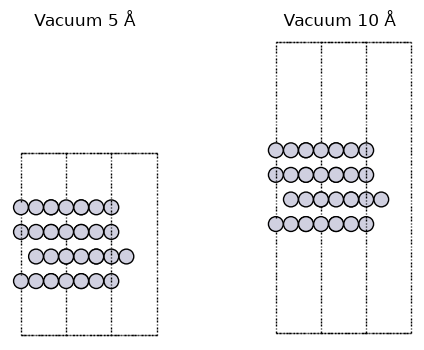

In [3]:
slab_334 = fcc111("Pt", size=(3, 3, 4), a=3.92, vacuum=10.0)
slab_334_thin = fcc111("Pt", size=(3, 3, 4), a=3.92, vacuum=5.0)

tags = slab_334.get_tags()

print("Atoms in the slab")
print(len(slab_334))
print("Layer index of each atom, 1 at the top")
print(tags)
print("Number of layers, the largest tag")
print(int(tags.max()))
print("Atoms in the top layer")
print(int((tags == 1).sum()))

print()
print("Cell vector lengths with 10 Å of vacuum (Å)")
print(np.round(slab_334.cell.lengths(), 3))
print("Cell angles with 10 Å of vacuum (°)")
print(np.round(slab_334.cell.angles(), 3))
print("Cell vector lengths with 5 Å of vacuum (Å)")
print(np.round(slab_334_thin.cell.lengths(), 3))

fig, axes = plt.subplots(1, 2, figsize=(6, 3.6), sharex=True, sharey=True)

plot_atoms(slab_334_thin, axes[0], radii=0.5, rotation="-90x")
axes[0].set_title("Vacuum 5 Å", fontsize=12)

plot_atoms(slab_334, axes[1], radii=0.5, rotation="-90x")
axes[1].set_title("Vacuum 10 Å", fontsize=12)

fig.tight_layout()
plt.show()

## 3. The general way: pymatgen SlabGenerator

- `ase.build` has a builder for a handful of named surfaces; pymatgen cuts any Miller index out of any crystal, which is what an oxide needs
- The starting point is a bulk crystal, read with pymatgen as in module 03
    - `Structure.from_file(path)` reads a structure file and gives a `Structure` back
    - `structures/Pt_bulk_fcc.vasp` holds the conventional cubic cell of platinum, 4 atoms, 3.92 Å on each side
    - Canon `S7`: in a project this file would be the bulk already optimized at the project's own level of theory, never the idealized coordinates a database served
- Building the generator
    - `from pymatgen.core.surface import SlabGenerator` brings in the tool
    - `SlabGenerator(bulk, miller_index=(1, 1, 1), min_slab_size=8.0, min_vacuum_size=10.0, center_slab=True)` describes the cut without making it yet
    - `miller_index=(1, 1, 1)` is the plane, in the sense of the word list above
    - `center_slab=True` puts the atoms in the middle of the cell, with the empty space split above and below them
    - Which tool and which settings a project uses is canon `S1`
- The two size arguments are requests, and they are not measured the way their names suggest
    - `min_slab_size=8.0` asks for at least 8 Å of slab, and the generator turns that into a whole number of bulk layers, here 4
    - Those 4 layers of atoms span 6.79 Å from the lowest to the highest, which is less than the 8 Å asked for, because the request counts the slab's share of the repeating cell and that share includes one interlayer gap
    - `min_vacuum_size=10.0` asks for at least 10 Å of empty space in the one gap between the slab and its next copy
    - ASE's `vacuum=10.0` in the section on the quick way means 10 Å on each side, so the same number describes twice the empty space there
    - Always measure the thickness and the gap you actually got, and never report the number you asked for
- Making the slabs
    - `generator.get_slabs()` returns a list of `Slab` objects, one per distinct termination
    - A metal with one atom per lattice point, as face-centred cubic platinum, gives one, which is the whole point of the comparison with `ase.build` here
    - `slab.shift` is where along the stacking direction the cut was made, as a fraction of the bulk repeat
    - `slab.normal` is the surface normal as a vector of length one, the direction the surface looks along
- Measuring the slab
    - `AseAtomsAdaptor.get_atoms(slab)` converts it to an ASE `Atoms` object, as in module 03
    - `slab.cart_coords` is the atom positions in Å, one row per atom
    - `np.dot(positions, normal)` gives each atom's height along the surface normal, which is the direction thickness has to be measured in
    - `np.sort(values)` puts those heights in order, and the four distinct values printed below are the four layers the generator decided on
    - The z coordinate is not that direction here: the two in-plane vectors of this cell are tilted out of the xy plane, and the section on the orthogonal cell shows what that costs and how to fix it
    - `min(slab.cell.lengths()[:2])` is the shorter of the two in-plane vectors, the quantity canon `S6` sets a floor on
- `pd.DataFrame(rows).to_string(index=False)` prints a list of dictionaries as an aligned table without row numbers, as in modules 01, 02 and 03
- In the table:
    - Two slabs of the same surface, one from each tool, measured the same way
    - The thickness agrees to the third decimal: both hold four layers of Pt(1 1 1), so the two tools built the same surface
    - The atom counts differ because the in-plane sizes differ: `ase.build` was asked for 3 by 3, the generator returns the smallest cell it can
    - The generator's 2.772 Å in-plane vector is far below the 7.5 Å of canon `S6`; the section on in-plane size repeats it until it clears the minimum

In [4]:
from pymatgen.core import Structure
from pymatgen.core.surface import SlabGenerator
from pymatgen.io.ase import AseAtomsAdaptor

pt_bulk = Structure.from_file(STRUCTURES / "Pt_bulk_fcc.vasp")
pt_generator = SlabGenerator(pt_bulk, miller_index=(1, 1, 1), min_slab_size=8.0,
                             min_vacuum_size=10.0, center_slab=True)
pt_slabs = pt_generator.get_slabs()
pt_slab_raw = pt_slabs[0]

print("Atoms in the bulk cell the slab was cut from")
print(pt_bulk.num_sites)
print("Terminations the generator found for Pt(1 1 1)")
print(len(pt_slabs))
print("Where the cut was made, as a fraction of the bulk repeat")
print(round(pt_slab_raw.shift, 4))
print("Surface normal of the generated slab")
print(np.round(pt_slab_raw.normal, 3))

pt_slab_ase = AseAtomsAdaptor.get_atoms(pt_slab_raw)
heights_normal = np.dot(pt_slab_raw.cart_coords, pt_slab_raw.normal)

print("Atom heights along the surface normal, lowest first (Å)")
print(np.round(np.sort(heights_normal), 3))

rows = [{"built by": "ase.build.fcc111, size (3, 3, 4)",
         "atoms": len(slab_334),
         "thickness (Å)": round(float(slab_334.positions[:, 2].max()
                                      - slab_334.positions[:, 2].min()), 3),
         "shortest in-plane vector (Å)": round(float(min(slab_334.cell.lengths()[:2])), 3)},
        {"built by": "pymatgen SlabGenerator, (1 1 1)",
         "atoms": len(pt_slab_ase),
         "thickness (Å)": round(float(heights_normal.max() - heights_normal.min()), 3),
         "shortest in-plane vector (Å)": round(float(min(pt_slab_ase.cell.lengths()[:2])), 3)}]

print()
print("The same Pt(1 1 1) surface from the two tools")
print(pd.DataFrame(rows).to_string(index=False))

Atoms in the bulk cell the slab was cut from
4
Terminations the generator found for Pt(1 1 1)
1
Where the cut was made, as a fraction of the bulk repeat
0.5
Surface normal of the generated slab
[0.577 0.577 0.577]
Atom heights along the surface normal, lowest first (Å)
[ 6.79   9.053 11.316 13.579]

The same Pt(1 1 1) surface from the two tools
                        built by  atoms  thickness (Å)  shortest in-plane vector (Å)
ase.build.fcc111, size (3, 3, 4)     36           6.79                         8.316
 pymatgen SlabGenerator, (1 1 1)      4           6.79                         2.772


## 4. Layers: count them yourself

- The number of layers is the first thing to check on any slab, and neither tool guarantees the number you asked for
    - `ase.build` was told `size=(3, 3, 4)` and gives 4; the generator was told `min_slab_size=8.0` and decided on 4 by itself
    - Counting from the coordinates is the check that does not depend on either promise
- How the counter works, in three steps
    1. Sort the atom heights: `np.sort(heights)`
    2. Find every place where the sorted heights jump by more than a tolerance: `np.diff(ordered)` gives the gaps, `np.where(gaps > tolerance)` gives their positions
    3. Cut the sorted list at those places: `np.split(ordered, breaks + 1)` returns one array of heights per layer
- `np.diff(values)` is the list of differences between neighbouring entries, so it is one entry shorter than what it was given
- `np.where(condition)` gives the positions where the condition is true, and `[0]` takes the first of the arrays it returns
- `np.split(values, positions)` cuts one array into several at the given positions, and `breaks + 1` shifts every position to the entry after the gap
- The tolerance is the whole decision, and it is canon `S2`
    - 0.5 Å is used here because the Pt(1 1 1) layers are 2.263 Å apart, so no reasonable tolerance can merge them
    - On an oxide the planes are much closer and can be rumpled, meaning the atoms of one plane sit at slightly different heights; the tolerance then decides the answer, as the section on terminations shows
    - On a stepped surface there is no single flat plane at all, and the count depends on what you agree to call one layer
    - Write the definition and the tolerance down in the project's `CANON.md` before you count, and use the same definition again when you decide how many layers to freeze under canon `S8`
- `group.mean()` is the average height of one layer, and `float(...)` turns it into a plain number for printing
- `values.append(x)` adds one entry to the end of a list, as in modules 02 and 03
- The slab counted here is the `ase.build` slab of the section on the quick way, at both tolerances

In [5]:
def count_layers(heights, tolerance=0.5):
    """Group atom heights into layers: sort them, then split where the gap exceeds the tolerance."""
    ordered = np.sort(heights)
    gaps = np.diff(ordered)
    breaks = np.where(gaps > tolerance)[0]
    return np.split(ordered, breaks + 1)


layers_05 = count_layers(slab_334.positions[:, 2], tolerance=0.5)
layers_01 = count_layers(slab_334.positions[:, 2], tolerance=0.1)

atoms_per_layer = []
mean_heights = []
for group in layers_05:
    atoms_per_layer.append(len(group))
    mean_heights.append(float(group.mean()))

print("Layers found in the ase.build slab, tolerance 0.5 Å")
print(len(layers_05))
print("Atoms in each layer, from the bottom up")
print(atoms_per_layer)
print("Height of each layer (Å)")
print(np.round(mean_heights, 3))
print("Spacing between neighbouring layers (Å)")
print(np.round(np.diff(mean_heights), 3))

print()
print("Layers found in the same slab, tolerance 0.1 Å")
print(len(layers_01))

Layers found in the ase.build slab, tolerance 0.5 Å
4
Atoms in each layer, from the bottom up
[9, 9, 9, 9]
Height of each layer (Å)
[10.    12.263 14.526 16.79 ]
Spacing between neighbouring layers (Å)
[2.263 2.263 2.263]

Layers found in the same slab, tolerance 0.1 Å
4


## 5. Terminations on a second material

- Co3O4 is the oxide of the group's e-waste project, and its (1 0 0) surface is the one the capstone works on
- The cut is set up exactly as for the metal, on the 56-atom conventional cell of module 03
    - `SlabGenerator(bulk, miller_index=(1, 0, 0), min_slab_size=8.0, min_vacuum_size=10.0)`
    - `center_slab` is left out here, so it keeps its default and the atoms sit at the bottom of the cell instead of the middle
    - That is cosmetic: the cell repeats, so where the atoms sit inside it changes no energy; a centred slab is only easier to look at and easier to cut by height
- `generator.get_slabs(symmetrize=False)` returns one `Slab` per termination
    - `symmetrize=True` would delete atoms from one face until the two faces match; on this cell at this thickness it removes so many atoms that it returns no slab at all, and warns about it
    - Whether a project wants symmetric slabs, and whether it accepts deleting atoms to get them, is canon `S3`
- Three questions are asked about each termination, and each one is a method on the `Slab` object
    - Stoichiometric means the slab holds the elements in the same ratio as the bulk; `slab.composition.reduced_formula` is `Co3O4` for both terminations here, so both are
    - A symmetric slab has the same atomic plane on top and on the bottom, so both faces are the same surface; `slab.is_symmetric()` answers it
    - A polar surface carries a net electric dipole across the slab, which makes its energy grow with thickness instead of settling; `slab.is_polar()` answers it
- `slab.is_polar()` needs charges, and gives a misleading answer without them
    - It works out the dipole from the charge on each site, and a structure read from a `POSCAR` carries no charges at all
    - With no charges every dipole is zero, so the answer is `False` for every slab, whatever the surface really is
    - `slab.add_oxidation_state_by_guess()` puts a guessed charge on every site, here `Co2.67+` and `O2-`, and the same two slabs then answer `True`
    - `Co2.67+` is an average over the whole composition, not a real charge: the spinel holds `Co2+` on its tetrahedral sites and `Co3+` on its octahedral ones, and the guess does not know which site is which
    - What `is_polar()` then answers is a test on those formal charges, not a dipole computed by any calculation; the verdict that the surface is polar stands, and no number about its size follows from it
    - `slab.copy()` is used first, so the guessed charges stay out of the structures written to disk later
    - This is the shape of a silent failure worth remembering: a tool answered a question it had not been given the information to answer
- A polar surface is not a reason to stop, but it is a reason to change the recipe
    - The two faces of a polar slab are different and their energies cannot be separated from one calculation
    - The project's answer is to build complementary pairs, where two slabs together carry the atoms one bulk repeat holds, and to use the pair
    - The project track holds the generator that does this, `projects/ew2gc/examples/gen_slabs_sharable.py`, and the capstone runs it and explains the pairs
- Why an oxide has more terminations than this metal
    - A metal with one atom per lattice point, as face-centred cubic platinum has, repeats one kind of atomic plane, so wherever the cut falls it exposes the same plane: one termination
    - That reasoning covers the face-centred cubic, body-centred cubic and simple cubic metals, and one element is not enough to make it true
    - Hexagonal close-packed cobalt metal has two terminations on its `(1 0 -1 0)` face, which is `miller_index=(1, 0, 0)` in the three numbers the generator takes, and an element in the diamond structure has two on `(1 1 1)`
    - An oxide stacks planes of different composition, so a cut between one pair of planes exposes metal and a cut between the next pair exposes oxygen; each distinct cut is another termination, and the count grows with the number of distinct planes in the repeat
    - The count is therefore something to measure with `get_slabs()` on the surface you actually want, and never something to assume from the chemical formula
- `enumerate(list)` hands out the position and the item together, as in module 01, which is how each termination gets its number in the table and in the figure
- The layer counter of the section above is used again, at two tolerances, on the first termination
    - The two answers differ, which is the oxide case the previous section warned about, and it is exactly what canon `S2` exists to settle
- In the table:
    - Two terminations, both with 28 atoms and both `Co3O4`, so both are stoichiometric
    - Neither is symmetric, so top and bottom are different surfaces in both
    - `polar, no charges` is `False` for both and means nothing; `polar, charges guessed` is `True` for both and is the answer to read
- In the figure:
    - The two terminations side by side, side views, with oxygen small and red and cobalt large and pink
    - The top plane differs between the panels, which is what the word termination means
    - The atoms sit at the bottom of the cell in both, because `center_slab` was left out

Atoms in the bulk cell the slabs were cut from
56
Terminations the generator found for Co3O4(1 0 0)
2

Every termination of Co3O4(1 0 0) at this thickness
 termination  shift  atoms formula  symmetric  polar, no charges  polar, charges guessed
           0 0.0560     28   Co3O4      False              False                    True
           1 0.1185     28   Co3O4      False              False                    True

Shortest in-plane vector of the oxide slabs (Å)
5.689
Height groups in termination 0, tolerance 0.5 Å
8
Height groups in termination 0, tolerance 0.1 Å
16


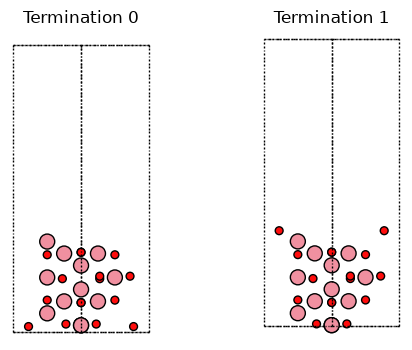

In [6]:
co_bulk = Structure.from_file(STRUCTURES / "Co3O4_mp-18748.vasp")
co_generator = SlabGenerator(co_bulk, miller_index=(1, 0, 0), min_slab_size=8.0,
                             min_vacuum_size=10.0)
co_terminations = co_generator.get_slabs(symmetrize=False)

print("Atoms in the bulk cell the slabs were cut from")
print(co_bulk.num_sites)
print("Terminations the generator found for Co3O4(1 0 0)")
print(len(co_terminations))

rows = []
for index, termination in enumerate(co_terminations):
    charged = termination.copy()
    charged.add_oxidation_state_by_guess()
    rows.append({"termination": index,
                 "shift": round(termination.shift, 4),
                 "atoms": termination.num_sites,
                 "formula": termination.composition.reduced_formula,
                 "symmetric": termination.is_symmetric(),
                 "polar, no charges": termination.is_polar(),
                 "polar, charges guessed": charged.is_polar()})

print()
print("Every termination of Co3O4(1 0 0) at this thickness")
print(pd.DataFrame(rows).to_string(index=False))

co_slab_ase = AseAtomsAdaptor.get_atoms(co_terminations[0])

print()
print("Shortest in-plane vector of the oxide slabs (Å)")
print(round(float(min(co_slab_ase.cell.lengths()[:2])), 3))
print("Height groups in termination 0, tolerance 0.5 Å")
print(len(count_layers(co_slab_ase.positions[:, 2], tolerance=0.5)))
print("Height groups in termination 0, tolerance 0.1 Å")
print(len(count_layers(co_slab_ase.positions[:, 2], tolerance=0.1)))

fig, axes = plt.subplots(1, 2, figsize=(6, 3.6), sharex=True, sharey=True)
for index, ax in enumerate(axes):
    plot_atoms(AseAtomsAdaptor.get_atoms(co_terminations[index]), ax,
               radii=0.5, rotation="-90x")
    ax.set_title("Termination " + str(index), fontsize=12)
fig.tight_layout()
plt.show()

## 6. In-plane size

- The in-plane size decides how far an adsorbate sits from its own periodic copy, and with it whether an adsorption energy describes one molecule or a dense layer
    - Module 02 made the same point on the bulk cell; here it decides the size of every slab of the rest of the course
- Canon `S6`, settled for the group: the shortest in-plane lattice vector of a surface or adsorption cell is about 7.5 Å
    - Any vector below that is repeated until it clears the minimum
    - The "about" absorbs hundredths of an ångström, not whole ones
    - A project may build larger cells than the minimum requires, and some do
- The starting point here is the smallest Pt(1 1 1) slab, one atom per layer, four layers
    - `fcc111("Pt", size=(1, 1, 4), a=3.92, vacuum=10.0)` builds it
    - `slab.repeat((n, n, 1))` repeats it `n` times along each in-plane vector and leaves the stacking direction alone, as in module 02
    - The cost grows with the square of `n`: 4 atoms, then 16, then 36, then 64
- In the table:
    - The 1 by 1 and 2 by 2 cells are below the 7.5 Å minimum and are not usable for an adsorption calculation
    - 3 by 3 is the first that clears it, at 8.316 Å, and it is the size this course uses from module 05 on
    - 4 by 4 clears it with room to spare and costs nearly twice the atoms of 3 by 3
    - The oxide slabs of the section on terminations have a shortest in-plane vector of 5.689 Å, so they would need the same treatment before any adsorbate is placed on them
- In the figure:
    - Top views of the three larger cells, drawn at one scale because the panels share their axes
    - The atoms are the same size in every panel; it is the cell that grows

In-plane size of the Pt(1 1 1) slab against canon S6
in-plane size  atoms  shortest in-plane vector (Å)  clears the 7.5 Å minimum
        1 x 1      4                         2.772                     False
        2 x 2     16                         5.544                     False
        3 x 3     36                         8.316                      True
        4 x 4     64                        11.087                      True


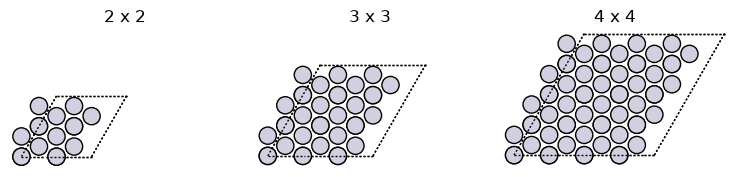

In [7]:
base_slab = fcc111("Pt", size=(1, 1, 4), a=3.92, vacuum=10.0)

rows = []
for n in (1, 2, 3, 4):
    repeated = base_slab.repeat((n, n, 1))
    shortest = float(min(repeated.cell.lengths()[:2]))
    rows.append({"in-plane size": str(n) + " x " + str(n),
                 "atoms": len(repeated),
                 "shortest in-plane vector (Å)": round(shortest, 3),
                 "clears the 7.5 Å minimum": bool(shortest >= 7.5)})

print("In-plane size of the Pt(1 1 1) slab against canon S6")
print(pd.DataFrame(rows).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(7.5, 2.8), sharex=True, sharey=True)
for panel, n in enumerate((2, 3, 4)):
    plot_atoms(base_slab.repeat((n, n, 1)), axes[panel], radii=0.5)
    axes[panel].set_title(str(n) + " x " + str(n), fontsize=12)
fig.tight_layout()
plt.show()

## 7. Freeze the bottom

- The bottom layers of a slab are frozen so that they keep the geometry of the bulk material while the surface relaxes
    - Without them the whole slab relaxes, and a four-layer piece of metal is not a bulk crystal, so the result describes a thin film
    - How many layers are frozen is canon `S8`, decided per project and counted in the layer definition of canon `S2`
    - One layer of three is frozen here, which is a teaching value chosen to keep this course fast
- The constraint is built from the tags of the section on the quick way, so no height arithmetic is needed
    - `tags.max()` is the tag of the bottom layer, because tag 1 is the top and the tags count downward
    - `enumerate(tags)` hands out the index and the tag together, and the loop keeps the index of every atom whose tag matches
    - `FixAtoms(indices=[...])` fixes those atoms in all three directions, as in module 02
    - `slab.set_constraint(...)` attaches the rule to the structure, and it then travels with it into the file
- Writing it as a `POSCAR`, with the three arguments of module 02
    - `write(path, slab, format="vasp", direct=True, sort=True)` writes the VASP format, in fractional coordinates, with the atoms grouped by species
    - A line reading `Selective dynamics` appears above the line `Direct`, and every atom line then ends with three flags: `F F F` for a fixed atom, `T T T` for a free one
- The order of the atoms in the file is not the order of the atoms in the `Atoms` object, and this is true even with one chemical species
    - `sort=True` sorts by species with a method that is free to reorder atoms it considers equal, and with one species it considers all of them equal
    - The flags follow their own atoms, so the file is correct; it is the index list that changed
    - The index list printed below may differ on your computer: a sort is free to arrange in any order the atoms it considers equal, and different versions of the tools make different choices
    - Never identify a fixed atom in the file by the index it had in the `Atoms` object; read the file back and check
- The check that matters is printed below: the structure is read back and the heights of its fixed atoms are listed
    - `np.unique(values)` gives the distinct values of an array, in order
    - `np.delete(values, positions)` gives the array back without the entries at those positions, which is how the free atoms are separated from the fixed ones here
    - One height for the fixed atoms, the lowest, means the frozen set is exactly the bottom layer
- `scripts/onboarding_structures.py` in this repository holds `pt111_slab(size=(3, 3, 3), vacuum=10.0, fix_bottom_layers=1)`, which is this whole section in one line
    - Module 05 onward imports it instead of repeating these lines, and it uses the same teaching values
- `path.read_text()` reads a whole text file into one piece of text, and `[:420]` keeps its first 420 characters

In [8]:
from ase.constraints import FixAtoms
from ase.io import read, write

slab_333 = fcc111("Pt", size=(3, 3, 3), a=3.92, vacuum=10.0)
tags_333 = slab_333.get_tags()
bottom_tag = int(tags_333.max())

bottom = []
for index, tag in enumerate(tags_333):
    if tag == bottom_tag:
        bottom.append(index)

slab_333.set_constraint(FixAtoms(indices=bottom))

print("Layers in this slab")
print(bottom_tag)
print("Indices of the fixed atoms in the Atoms object")
print(bottom)
print("Atoms free to move")
print(len(slab_333) - len(bottom))

poscar = WORK / "POSCAR_Pt111_frozen"
write(poscar, slab_333, format="vasp", direct=True, sort=True)

print()
print("First 420 characters of the POSCAR file")
print(poscar.read_text()[:420])

back = read(poscar)
fixed_in_file = back.constraints[0].get_indices()

print()
print("Indices of the fixed atoms after reading the file back")
print(fixed_in_file)
print("Distinct heights of the fixed atoms in the file (Å)")
print(np.unique(np.round(back.positions[fixed_in_file, 2], 3)))
print("Distinct heights of the free atoms in the file (Å)")
print(np.unique(np.round(np.delete(back.positions[:, 2], fixed_in_file), 3)))

Layers in this slab
3
Indices of the fixed atoms in the Atoms object
[0, 1, 2, 3, 4, 5, 6, 7, 8]
Atoms free to move
18

First 420 characters of the POSCAR file
Pt
 1.0000000000000000
     8.3155757467537992    0.0000000000000000    0.0000000000000000
     4.1577878733768996    7.2014998437825426    0.0000000000000000
     0.0000000000000000    0.0000000000000000   24.5264261104466641
 Pt 
  27
Selective dynamics
Direct
  0.1111111111111111  0.1111111111111111  0.4077234879214893   F   F   F
  0.0000000000000000  0.6666666666666666  0.5922765120785108   T   T   T
  0.6666666

Indices of the fixed atoms after reading the file back
[ 0 17 18 19 20 21 22 23 24]
Distinct heights of the fixed atoms in the file (Å)
[10.]
Distinct heights of the free atoms in the file (Å)
[12.263 14.526]


## 8. Orthogonal cell and the surface normal

- Freezing by tag worked in the section above because `ase.build` builds its slabs with the surface normal along z
- A slab from `SlabGenerator` carries no tags, so the bottom layer has to be found from the coordinates, and that only works when z really is the surface normal
    - The Pt slab built in the section on the general way has its two in-plane vectors tilted out of the xy plane, at cell angles of 135°
    - Its surface normal is the (1 1 1) direction of the cube, not z
    - An orthogonal cell is one whose third cell vector is perpendicular to the other two; in a slab that makes the third vector the surface normal and puts the layers at constant z
- What goes wrong when the normal is not z, measured below
    - In the one-atom-per-layer cell the atoms still come out at four distinct z values, so a layer count looks right by accident
    - Repeat that same cell 2 by 2 in plane, as canon `S6` requires, and every copy is shifted in z as well as in plane, because the in-plane vectors themselves carry z
    - The four layers then spread over nine distinct heights, and every recipe that picks atoms by height picks the wrong ones
- `slab.get_orthogonal_c_slab()` is the fix, and it changes no chemistry
    - It rotates the structure so that the third cell vector is perpendicular to the in-plane pair, and it moves no atom relative to its neighbours
    - The in-plane vector lengths and the angle between them are unchanged; the cell angles to the third vector become 90°
    - The length of the third vector changes, because the tilted vector was longer than the distance it spanned along the normal
    - The group's own slab generator does this, which is why its files can be cut by height and frozen by height
- `slab.lattice.matrix` is the cell as three rows, one per cell vector, in Å; `slab.lattice.angles` gives the three angles in degrees
- The layer counter of the section on layers is used again, on the 2 by 2 repeat before and after the fix
- In the printed comparison:
    - Before: cell angles 135°, 135°, 60°, third vector 35.28 Å long, surface normal pointing along (1 1 1)
    - After: cell angles 90°, 90°, 60°, third vector 20.369 Å, surface normal along z
    - The 1 by 1 cell has 4 height groups before the fix, which is the right answer reached by accident
    - The 2 by 2 repeat has 9 height groups before and 4 after, for the same 16 atoms
    - The atoms span 6.79 Å and the empty gap is 13.579 Å, against the 8 Å and the 10 Å asked for in the section on the general way
    - The generator counts in whole bulk layers, which is why the slab measures less than its request while the gap measures more

In [9]:
pt_slab_ortho = pt_slab_raw.get_orthogonal_c_slab()

raw_repeat = AseAtomsAdaptor.get_atoms(pt_slab_raw).repeat((2, 2, 1))
ortho_repeat = AseAtomsAdaptor.get_atoms(pt_slab_ortho).repeat((2, 2, 1))

print("Cell as the generator built it, one row per cell vector (Å)")
print(np.round(pt_slab_raw.lattice.matrix, 3))
print("Cell angles as built (°)")
print(np.round(pt_slab_raw.lattice.angles, 3))
print("Surface normal as built")
print(np.round(pt_slab_raw.normal, 3))

print()
print("Cell after get_orthogonal_c_slab, one row per cell vector (Å)")
print(np.round(pt_slab_ortho.lattice.matrix, 3))
print("Cell angles after get_orthogonal_c_slab (°)")
print(np.round(pt_slab_ortho.lattice.angles, 3))
print("Surface normal after get_orthogonal_c_slab")
print(np.round(pt_slab_ortho.normal, 3))

print()
print("Height groups in the 1 by 1 cell as built, tolerance 0.5 Å")
print(len(count_layers(pt_slab_ase.positions[:, 2], tolerance=0.5)))
print("Atoms in the 2 by 2 repeat, the same before and after")
print(len(raw_repeat))
print("Height groups in the 2 by 2 repeat as built, tolerance 0.5 Å")
print(len(count_layers(raw_repeat.positions[:, 2], tolerance=0.5)))
print("Height groups in the 2 by 2 repeat after the fix, tolerance 0.5 Å")
print(len(count_layers(ortho_repeat.positions[:, 2], tolerance=0.5)))

ortho_heights = np.dot(pt_slab_ortho.cart_coords, pt_slab_ortho.normal)
thickness = float(ortho_heights.max() - ortho_heights.min())

print()
print("Thickness of the slab along the surface normal (Å)")
print(round(thickness, 3))
print("Empty gap between the slab and its next copy (Å)")
print(round(float(pt_slab_ortho.lattice.c - thickness), 3))

Cell as the generator built it, one row per cell vector (Å)
[[ 1.96  0.   -1.96]
 [ 0.    1.96 -1.96]
 [ 0.    0.   35.28]]
Cell angles as built (°)
[135. 135.  60.]
Surface normal as built
[0.577 0.577 0.577]

Cell after get_orthogonal_c_slab, one row per cell vector (Å)
[[ 2.772  0.     0.   ]
 [ 1.386  2.4    0.   ]
 [ 0.     0.    20.369]]
Cell angles after get_orthogonal_c_slab (°)
[90. 90. 60.]
Surface normal after get_orthogonal_c_slab
[-0. -0.  1.]

Height groups in the 1 by 1 cell as built, tolerance 0.5 Å
4
Atoms in the 2 by 2 repeat, the same before and after
16
Height groups in the 2 by 2 repeat as built, tolerance 0.5 Å
9
Height groups in the 2 by 2 repeat after the fix, tolerance 0.5 Å
4

Thickness of the slab along the surface normal (Å)
6.79
Empty gap between the slab and its next copy (Å)
13.579


## 9. Save the slabs you will use

- Two files are written here, one per material, and both are for your own use
    - `work/Pt111_3x3x3.vasp` is the frozen three-layer Pt(1 1 1) slab of the section on freezing the bottom
    - `work/Co3O4_100_t0.vasp` is termination 0 of Co3O4(1 0 0), from the section on terminations
- The later modules do not read these files
    - Module 05 onward builds its own Pt slab with `pt111_slab` from `scripts/onboarding_structures.py`, so that each notebook runs on its own
    - These two are here so that you can open them in `ase gui`, measure them, and compare them with what the group's scripts produce
- Two writers, one for each package
    - `write(path, atoms, format="vasp", direct=True, sort=True)` writes an ASE `Atoms` object, and carries the constraint into the file as the `F F F` flags
    - `structure.to(filename=..., fmt="poscar")` writes a pymatgen `Structure`, as in module 03; it carries no constraint, because the oxide slab has none
- Both files are read back with ASE and checked, which is the only way to know a write worked
    - `len(atoms.constraints)` is 0 when nothing is fixed, so the count of fixed atoms is read only when there is a constraint to read it from
- Canon `S9`: neither of these slabs may be relaxed with its cell free
    - The lateral cell parameters come from the optimized bulk, and a slab that relaxes its own cell throws that away
    - The relaxations of module 06 onward move the atoms only
- In the table:
    - One row per file written, with what ASE reads back out of it
    - 9 fixed atoms in the Pt file, the bottom layer of 27; none in the oxide file

In [10]:
pt_path = WORK / "Pt111_3x3x3.vasp"
co_path = WORK / "Co3O4_100_t0.vasp"

write(pt_path, slab_333, format="vasp", direct=True, sort=True)
co_terminations[0].to(filename=str(co_path), fmt="poscar")

rows = []
for path in (pt_path, co_path):
    atoms = read(path)
    n_fixed = len(atoms.constraints[0].get_indices()) if atoms.constraints else 0
    rows.append({"file": path.name,
                 "atoms": len(atoms),
                 "formula": atoms.get_chemical_formula(),
                 "fixed atoms": n_fixed,
                 "cell height (Å)": round(float(atoms.cell.lengths()[2]), 3)})

print("Files written into the work folder, then read back")
print(pd.DataFrame(rows).to_string(index=False))

Files written into the work folder, then read back
             file  atoms formula  fixed atoms  cell height (Å)
 Pt111_3x3x3.vasp     27    Pt27            9           24.526
Co3O4_100_t0.vasp     28 Co12O16            0           24.138


## Check yourself

1. Your generator gives a slab whose two in-plane vectors are 5.689 Å and 8.046 Å, and you intend to put one OH
   group on it. Which canon item does that cell break, what do you do to it, and what does that cost?
2. You cut a slab with `SlabGenerator`, print its cell angles and read 135°, 135° and 60°. You were about to freeze
   every atom below a chosen height. What goes wrong, and what do you do first?
3. Your layer counter finds 8 height groups in an oxide slab with a tolerance of 0.5 Å, and 16 groups with a
   tolerance of 0.1 Å. Which number is the number of layers?

<details>
<summary>Answers</summary>

- It breaks canon `S6`: the shortest in-plane vector, 5.689 Å, is below the 7.5 Å minimum, so the OH group would
  sit about 5.7 Å from its own periodic copy and the adsorption energy would describe a dense layer rather than one
  isolated group. Repeat the cell along that vector with `slab.repeat((2, 1, 1))`, which gives 11.378 Å and doubles
  the atom count, and check the other vector as well
- The z axis is not the surface normal in that cell: the in-plane vectors are tilted out of the xy plane, so atoms of
  one layer sit at different heights and a cut by height mixes layers. Call `slab.get_orthogonal_c_slab()` first,
  which makes the third cell vector the surface normal without moving any atom relative to its neighbours, then
  count the layers again and only then freeze
- Neither, by itself. "One layer" is a definition, not a measurement, and it is canon `S2`: your supervisor sets it
  and it is written in the project's `CANON.md` together with the tolerance used to apply it. Whatever is agreed,
  the same definition then has to be used again when canon `S8` says how many bottom layers to freeze

</details>